# Phase 3, Task 1 — Read the Confusion Matrix & Turn the Threshold Dial

Phase 2 answered *"is the model good?"*. Phase 3 answers the real SOC question: **"at what sensitivity do we run it?"**

Until now you've accepted whatever `.predict()` returned. But `.predict()` secretly means *"flag as attack only if the model is ≥ 50% sure."* **50% is an arbitrary default, not a law** — it's a dial you own. A detector that must never miss a breach flags at a *lower* bar (catch more, tolerate more false alarms); one drowning analysts in noise raises the bar.

To tune that dial you need two things:
1. The **confusion matrix** — the 4 raw counts behind every score, so you see the exact mistakes.
2. The model's **probabilities** (`predict_proba`), not just its 0/1 verdict, so you can re-decide at any cutoff.

**Vocabulary (define-as-we-go):**
- **TP** attack, caught · **FP** benign, wrongly flagged = *false alarm* · **FN** attack, missed = *the breach that walked in* · **TN** benign, correctly ignored.
- **Precision** = TP / (TP+FP) — when it flags, how often it's right. **Recall** = TP / (TP+FN) — of all real attacks, how many it caught. Both are just ratios of those 4 numbers.
- **False-positive cost / alert fatigue** = every FP burns analyst time; too many and the team starts ignoring alerts, so real ones get missed too. You can't max precision AND recall — you *choose* the balance.

## Step 0 — Rebuild the substrate (reuse your Task 5 work)
We need a model with **real misses** to analyze — a perfect 1.00/1.00 model has nothing to tune. So reuse the **held-out `model2` from Task 5's stretch**: trained on the 7 days *minus* PortScan. Its ~31k missed PortScans (plus any borderline cases) are our raw material.

**Your job:** reproduce, from your Task 5 notebook, everything up to and including `model2`:
- load + `load_clean` the 7 day CSVs → `pd.concat` into one `df` (keep `Label`)
- build `is_attack`, `X`, `y`; stratified 80/20 split, **also capturing `label_test`** (the attack name per test row) and `lab_train`
- `mask = lab_train != 'PortScan'` → train `model2` on `X_train[mask], y_train[mask]`

**Hint:** you already wrote all of this — copy your own cells over. End this step with `model2`, `X_test`, `y_test`, `label_test` all defined. (Sanity check: `y_test.mean()` ≈ 0.22 attack rate.)

In [2]:
import pandas as pd
import numpy as np 

In [3]:
# TODO: reproduce Task 5 up to model2 (7 days minus PortScan). End with model2, X_test, y_test, label_test defined.

df_mon=pd.read_csv("/Users/rohanb/06_projects/CYBERSECURITY/data/EXTRA/Monday-WorkingHours.pcap_ISCX.csv")
df_tue=pd.read_csv("/Users/rohanb/06_projects/CYBERSECURITY/data/EXTRA/Tuesday-WorkingHours.pcap_ISCX.csv")
df_wed=pd.read_csv("/Users/rohanb/06_projects/CYBERSECURITY/data/raw/CICIDS2017/Wednesday-workingHours.pcap_ISCX.csv")
df_thu_mor=pd.read_csv("/Users/rohanb/06_projects/CYBERSECURITY/data/EXTRA/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv")
df_thu_after=pd.read_csv("/Users/rohanb/06_projects/CYBERSECURITY/data/EXTRA/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv")
df_fri_mor=pd.read_csv("/Users/rohanb/06_projects/CYBERSECURITY/data/EXTRA/Friday-WorkingHours-Morning.pcap_ISCX.csv")
df_fri_after_Ps=pd.read_csv("/Users/rohanb/06_projects/CYBERSECURITY/data/EXTRA/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv")
df_fri_after_DDos=pd.read_csv("/Users/rohanb/06_projects/CYBERSECURITY/data/EXTRA/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")

In [4]:
def load_clean(df):
    df.columns=df.columns.str.strip()
    df=df.replace([np.inf,-np.inf],np.nan)
    df=df.dropna()
    return df
dfs=[load_clean(d) for d in [df_mon,df_tue,df_wed,df_thu_mor,df_thu_after,df_fri_mor,df_fri_after_Ps,df_fri_after_DDos]]
df=pd.concat(dfs,ignore_index=True)
df.isna().sum().sum()
np.isinf(df.select_dtypes('number')).sum().sum()
df['Label'].value_counts()

    

Label
BENIGN                        2271320
DoS Hulk                       230124
PortScan                       158804
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

the pandas index is a sticky ID

In [5]:
df["is_attack"]=(df['Label']!='BENIGN').astype(int)
df['is_attack'].value_counts()
X=df.drop(columns=['Label','is_attack'])
y=df['is_attack']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test, lab_train, label_test = train_test_split(X,y,df['Label'], test_size=0.2, random_state=42, stratify=y)
label_test=df.loc[X_test.index, 'Label']
label_test.value_counts()
mask=lab_train!='PortScan'
X_tr2, y_tr2 = X_train[mask], y_train[mask]

In [6]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_tr2, y_tr2)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [7]:
from sklearn.metrics import classification_report
y_pred=model.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.93      1.00      0.97    454265
           1       1.00      0.72      0.83    111311

    accuracy                           0.94    565576
   macro avg       0.97      0.86      0.90    565576
weighted avg       0.95      0.94      0.94    565576



In [8]:
res= pd.DataFrame({'true':y_test.values, "pred": y_pred, "label":label_test.values})
res[res.true == 1].groupby('label')['pred'].mean()

label
Bot                           0.776596
DDoS                          0.999687
DoS GoldenEye                 0.999523
DoS Hulk                      0.998833
DoS Slowhttptest              0.998153
DoS slowloris                 0.998227
FTP-Patator                   1.000000
Heartbleed                    1.000000
Infiltration                  0.600000
PortScan                      0.001109
SSH-Patator                   0.997523
Web Attack � Brute Force      0.993103
Web Attack � Sql Injection    0.333333
Web Attack � XSS              0.944444
Name: pred, dtype: float64

## Step 1 — Get probabilities, not labels
`.predict()` throws away *how sure* the model is. `predict_proba` keeps it — that confidence is exactly what the threshold dial acts on.

**Your job:** get the attack-probability for every test row and eyeball a few.

**Hints:**
- `proba = model2.predict_proba(X_test)[:, 1]` — `predict_proba` returns TWO columns: `[:, 0]` = P(benign), `[:, 1]` = P(attack). You want column 1.
- Look at `proba[:20]`. Notice most values sit near 0 or near 1 — random forests are confident. Keep that in mind for Step 5.

In [9]:
# TODO: proba = P(attack) for each test row; eyeball the first 20
proba=model.predict_proba(X_test)[:,1]
print(proba[:20])

[1.   1.   1.   0.   1.   0.   0.01 0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.   0.   0.   0.  ]


## Step 2 — The confusion matrix at the default 0.50
The confusion matrix is the 4 raw counts that *every* score is built from. See the mistakes directly.

**Your job:** turn `proba` into 0/1 at the default cutoff and print the confusion matrix.

**Hints:**
- `y_pred = (proba >= 0.5).astype(int)`
- `from sklearn.metrics import confusion_matrix` → `confusion_matrix(y_test, y_pred)` prints `[[TN, FP], [FN, TP]]` (rows = actual, cols = predicted, for labels 0 then 1).
- Sanity-check: recall = TP / (TP + FN). Does it match the ~0.71 attack recall you got in the Task 5 stretch?

In [10]:
# TODO: y_pred at 0.50; print confusion_matrix(y_test, y_pred)
y_pred = (proba >= 0.5).astype(int)
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test,y_pred))

# [[454153    112]  --> [TN, FP]
#  [ 31700  79611]] --> [FN, TP]

[[454153    112]
 [ 31700  79611]]


### ✍️ Label the four numbers (in your own words)
Fill these in from your matrix above — this is the vocabulary sticking:

- **TN** (benign, correctly ignored) = ?
- **FP** (false alarms — benign flagged as attack) = ?
- **FN** (missed attacks — the breaches that walked in) = ?
- **TP** (attacks caught) = ?

Which single number is the one a SOC fears most, and why?

## Step 3 — Turn the dial
Now move the cutoff and watch precision and recall trade against each other.

**Your job:** for each threshold `t` in `[0.1, 0.3, 0.5, 0.7, 0.9]`, recompute predictions and print the attack-class **recall AND precision**.

**Hints:**
- A small loop beats 5 copy-pasted cells: `for t in [...]:` then `y_t = (proba >= t).astype(int)`.
- `from sklearn.metrics import recall_score, precision_score` → `recall_score(y_test, y_t)`, `precision_score(y_test, y_t)`.
- Print like `f"t={t}: recall={r:.3f} precision={p:.3f}"`.
- **Watch the direction:** as `t` drops, which one climbs and which one falls? Say it out loud before moving on.

In [11]:
# TODO: loop thresholds 0.1..0.9; print attack recall + precision at each
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    y_t=(proba>=t).astype(int)
    from sklearn.metrics import recall_score, precision_score
    print(f"t={t}: recall={recall_score(y_test,y_t)}, precision={precision_score(y_test,y_t)}")

t=0.1: recall=0.7171258905229492, precision=0.9916517590936196
t=0.3: recall=0.71611071682044, precision=0.9973724052501846
t=0.5: recall=0.7152123330129098, precision=0.9985951356572131
t=0.7: recall=0.7141073209296476, precision=0.9992708621426596
t=0.9: recall=0.7110977351744212, precision=0.9996842557276011


## Step 4 — Draw the trade-off (the PR curve)
Those 5 points are a sample of a continuous curve. The full precision-recall curve *is* the menu of every operating point you could choose.

**Your job:** compute and plot the precision-recall curve.

**Hints:**
- `from sklearn.metrics import precision_recall_curve` → `precision, recall, thr = precision_recall_curve(y_test, proba)`.
- `import matplotlib.pyplot as plt` → `plt.plot(recall, precision)`; label the axes (x = recall, y = precision), add a title.
- Where the curve stays high-and-flat you get recall almost for free; where it suddenly drops is the price of chasing the last few attacks.

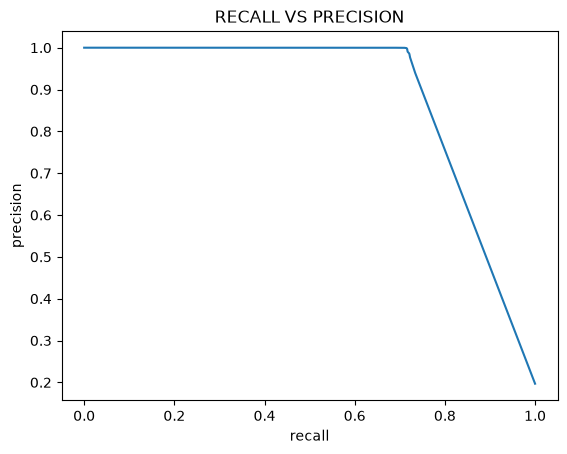

In [14]:
# TODO: precision_recall_curve(y_test, proba); plot recall (x) vs precision (y)
from sklearn.metrics import precision_recall_curve
precision, recall, thr = precision_recall_curve(y_test, proba)
import matplotlib.pyplot as plt
plt.title("RECALL VS PRECISION")
plt.xlabel("recall")
plt.ylabel("precision")
plt.plot(recall, precision)

## Step 5 — Make an engineering decision (and state its price)
This is the actual job: pick an operating point on purpose, in numbers.

**Your job:** set a goal — e.g. *"catch ≥ 90% of attacks"* — find the **lowest threshold** that hits it, then report the **cost**: how many more false alarms (FP) than the default 0.50? Is the trade worth it?

**Hints:**
- From the `precision_recall_curve` arrays, find where `recall >= 0.90` and read off the matching threshold (`thr` is aligned to `precision[:-1]`/`recall[:-1]`).
- Then rebuild `y_pred` at that threshold and compare its confusion matrix (esp. the FP count) to Step 2's.
- There is no single right answer — the skill is *stating the trade-off in numbers*, not finding a magic cutoff.

In [13]:
# Goal: catch >= 90% of attacks. Find the lowest threshold that hits it, and price the move vs the 0.50 default.
from sklearn.metrics import confusion_matrix

target = 0.90

# precision_recall_curve gives recall DECREASING as threshold INCREASES.
# recall[:-1] / precision[:-1] line up 1:1 with thr (thr has one fewer element).
meets = recall[:-1] >= target

if meets.any():
    # lowest threshold meeting the goal == highest recall point that still clears the bar
    t_star = thr[meets].min()
    print(f"Goal recall >= {target}: usable threshold = {t_star:.4f}")
else:
    t_star = thr.min()  # most aggressive cutoff the data offers (just above proba 0)
    print(f"Goal recall >= {target} is UNREACHABLE at any positive threshold.")
    print(f"Best recall the dial can buy = {recall[:-1].max():.4f} (at threshold {t_star:.4f})")

# Price the chosen operating point against the 0.50 default
cm_def  = confusion_matrix(y_test, (proba >= 0.50).astype(int))
cm_star = confusion_matrix(y_test, (proba >= t_star).astype(int))
tp_def, fn_def, fp_def = cm_def[1, 1], cm_def[1, 0], cm_def[0, 1]
tp_star, fn_star, fp_star = cm_star[1, 1], cm_star[1, 0], cm_star[0, 1]

print(f"\n                    default 0.50  ->  t*={t_star:.4f}")
print(f"  TP (caught)        {tp_def:>8}  ->  {tp_star:>8}  (+{tp_star - tp_def})")
print(f"  FN (missed)        {fn_def:>8}  ->  {fn_star:>8}")
print(f"  FP (false alarms)  {fp_def:>8}  ->  {fp_star:>8}  (+{fp_star - fp_def})")
print(f"\nThe trade: {tp_star - tp_def} more attacks caught for {fp_star - fp_def} more false alarms.")


Goal recall >= 0.9: usable threshold = 0.0000

                    default 0.50  ->  t*=0.0000
  TP (caught)           79611  ->    111311  (+31700)
  FN (missed)           31700  ->         0
  FP (false alarms)       112  ->    454265  (+454153)

The trade: 31700 more attacks caught for 454153 more false alarms.


## Step 6 — Interpret (for LEARNING_LOG, your own words)
You'll likely see one of two honest outcomes — **both are the lesson**:
1. For *borderline* errors, lowering the threshold recovers real attacks at the cost of more false alarms — **the dial works.**
2. For the held-out **PortScan**, the model is *confidently* wrong (its `proba` ≈ 0), so even a very low threshold barely recovers it — **threshold tuning fixes borderline cases, not blind spots.**

Answer:
1. Which way did recall and precision move as you dropped the threshold, and why?
2. Did lowering the threshold recover much of the missed PortScan? What does that tell you about the *kind* of error threshold tuning can and can't fix?
3. In one sentence: what does a detection engineer actually decide when they "set the threshold"?

---
### ✅ You pass Phase 3 Task 1 when:
1. You printed a **confusion matrix** and labelled its four cells (TP/FP/FN/TN) in your own words.
2. You produced a **precision/recall-vs-threshold** table and a **PR curve**.
3. You chose an operating threshold for a stated goal and reported its **false-positive cost in numbers**.
4. You can explain which misses threshold tuning fixes (borderline) and which it can't (confident blind spots).

Paste me your confusion matrix + threshold table + your Step 6 answers, and I'll review.